# Phase 2, step 1: build the INSTANCE training mixtures

Decisions used (from the team): earthquake pool = mean SNR >= 40 dB, 30,000 mixtures, all channel types, split by earthquake and by noise trace **before** mixing, bottlenecks later: `None` + `attention`.
Not yet decided by the team (defaults chosen by Claude, change in the settings cell): window starts 10 s before P; 2 noise windows of 60 s per 120 s noise trace; exclude source_id 1116011 (only candidate overlap with STEAD found in the inspection).

Needs: **Internet ON** (clones the repo for `utilities.downsample_series`), **Accelerator None**. Run time: a few minutes (estimate, not measured on the real data).
Output: `instance_mixtures/training_datasets_INSTANCE_snr40.hdf5` + `instance_build_report.json`. Use *Save & Run All*, then turn the output into a private Kaggle dataset.

In [1]:
import os, sys, json, glob, subprocess, hashlib, time
ON_KAGGLE = os.path.exists("/kaggle/input")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
TMP  = "/kaggle/temp" if ON_KAGGLE else os.path.join(os.getcwd(), "tmp")
os.makedirs(TMP, exist_ok=True)

# ---- settings
DOWNLOAD      = True      # True: download the INSTANCE sample v3 into TMP (needs Internet ON, 1.7 GB). False: use a Kaggle input dataset.
INSTANCE_DIR  = None       # None = search /kaggle/input for Instance_events_counts_10k.hdf5
N_MIXTURES    = 30000
SNR_MIN_DB    = 40.0
PRE_P_S       = 10.0
NOISE_WINDOWS = 2
EXCLUDE_SOURCE_IDS = [1116011]
OUT_DIR       = os.path.join(WORK, "instance_mixtures")
COMMIT        = "afe2536cf29ead8b4d8d5c50ddf85cc1dd90ddd1"     # repo commit used in Phase 1

In [2]:
# optional download (skip if the INSTANCE sample is attached as a Kaggle dataset)
import tarfile
if DOWNLOAD:
    dl = os.path.join(TMP, "instance"); os.makedirs(dl, exist_ok=True)
    tarf = os.path.join(dl, "sample_v3.tar.bz2")
    url = "http://repo.pi.ingv.it/instance/Instance_sample_dataset_v3.tar.bz2"
    if not os.path.exists(tarf):
        has_wget = subprocess.run("which wget", shell=True, capture_output=True).returncode == 0
        r = subprocess.run(["wget", "-q", "-O", tarf, url] if has_wget else ["curl", "-L", "-s", "-o", tarf, url]); print("download rc:", r.returncode)
    with tarfile.open(tarf, "r:bz2") as t: t.extractall(dl)
    os.remove(tarf); INSTANCE_DIR = dl
if INSTANCE_DIR is None:
    hits = glob.glob("/kaggle/input/**/Instance_events_counts_10k.hdf5", recursive=True)
    assert hits, "INSTANCE sample not found: attach it as an input dataset or set DOWNLOAD = True"
    INSTANCE_DIR = os.path.dirname(os.path.dirname(hits[0])) if os.path.basename(os.path.dirname(hits[0])) == "data" else os.path.dirname(hits[0])
print("INSTANCE_DIR:", INSTANCE_DIR)
for p in sorted(glob.glob(INSTANCE_DIR + "/**/*", recursive=True)):
    if os.path.isfile(p) and not os.path.basename(p).startswith("._"): print(f"  {os.path.getsize(p)/1e6:9.1f} MB  {os.path.relpath(p, INSTANCE_DIR)}")

download rc: 0


/tmp/ipykernel_16/2763522732.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tarf, "r:bz2") as t: t.extractall(dl)


INSTANCE_DIR: /kaggle/temp/instance
     1444.1 MB  data/Instance_events_counts_10k.hdf5
     1444.1 MB  data/Instance_events_gm_10k.hdf5
      144.4 MB  data/Instance_noise_1k.hdf5
       12.7 MB  metadata/metadata_Instance_events_10k.csv
        0.3 MB  metadata/metadata_Instance_noise_1k.csv


In [3]:
# repo at the pinned commit (for utilities.py only)
REPO = os.path.join(TMP, "WaveDecompNet-paper")
if not os.path.isdir(REPO):
    r = subprocess.run(f"git clone -q https://github.com/yinjiuxun/WaveDecompNet-paper {REPO} && git -C {REPO} checkout -q {COMMIT}", shell=True, capture_output=True, text=True)
    print("clone rc:", r.returncode, r.stderr[-300:])
UTIL_DIR = os.path.dirname(glob.glob(REPO + "/**/utilities.py", recursive=True)[0]); print("utilities.py in", UTIL_DIR)

clone rc: 0 
utilities.py in /kaggle/temp/WaveDecompNet-paper


In [4]:
SCRIPT = r'''"""new_step2b (INSTANCE): build earthquake + noise mixtures from the INSTANCE sample, same recipe as step2b.

What is the same as the repo's step2b (patched version):
  * downsample 100 Hz -> 10 Hz with the repo's own utilities.downsample_series (4th-order Butterworth low-pass at 5 Hz, then interpolation)
  * per-trace, per-component normalisation: (x - mean) / (std + 1e-12), for the earthquake and for the noise
  * random shift of the earthquake  U(-30, 60) s  (nearest-neighbour interp1d, zero fill), amplitude factor snr = 10 ** U(-1, 2)
  * stack, divide mixture AND earthquake by the std of the mixture, NaN -> 0
  * output X_train (mixture) and Y_train (earthquake only), shape (N, 600, 3), float64, plus 'time'

What is different (every item goes into the deviation log):
  * data: INSTANCE sample, raw COUNTS for earthquakes and noise (noise exists only in counts)
  * the 120 s trace is cropped to 60 s: [P - PRE_P_S, P - PRE_P_S + 60 s]
  * noise: each 120 s noise trace gives NOISE_WINDOWS non-overlapping 60 s windows
  * earthquake pool: mean of the three trace_[E,N,Z]_snr_db >= SNR_MIN_DB, P pick present, window inside the trace,
    listed source_ids excluded, windows with a flat component dropped
  * SPLIT BEFORE MIXING: unique earthquakes (source_id) and unique noise traces are split 60/20/20
    (same sklearn calls and seeds 13 / 20 as step3, but applied to earthquake ids / noise names, not to mixtures).
    Mixtures of a split only use earthquakes and noise of that split. Rows are written train | val | test and
    'split_id' (0, 1, 2) is stored so the training script can use it (step3 itself splits randomly after loading).
  * seeds: new seeds (the paper's 101..104 belong to STEAD): earthquake 201+split, noise 202+split ... see SEEDS below
  * per-sample metadata is written in the same file

Usage:
    python new_step2b_prepare_INSTANCE_waveforms.py --instance-dir /kaggle/input/instance --repo-dir /path/to/WaveDecompNet-paper \
        --out /kaggle/working/instance_mixtures
"""
import argparse
import glob
import hashlib
import json
import os
import sys
import time as t

import h5py
import numpy as np
import pandas as pd
from numpy.random import default_rng
from scipy.interpolate import interp1d
from sklearn.model_selection import train_test_split

FS = 100                    # Hz in the INSTANCE files (metadata trace_dt_s = 0.01 for all traces, seen in the inspection)
F_DOWNSAMPLE = 10           # Hz, as the repo
WIN_S = 60                  # s, window length
SEEDS = dict(earthquake=201, noise=202, shift=203, snr=204)   # new; split k uses earthquake+10*k and noise+10*k
SPLIT_SEED_1, SPLIT_SEED_2, TRAIN_SIZE, TEST_SIZE = 13, 20, 0.6, 0.5   # as step3 / config.py
SPLIT_NAMES = ["train", "val", "test"]


def find(root, *must, must_not=("._",)):
    hits = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
            if os.path.isfile(p) and all(m.lower() in os.path.basename(p).lower() for m in must)
            and not any(b in os.path.basename(p) for b in must_not)]
    return sorted(hits)


def pick_one(root, *must):
    hits = find(root, *must)
    if not hits:
        raise FileNotFoundError(f"no file with {must} under {root}")
    if len(hits) > 1:
        print(f"WARNING: several matches for {must}: {hits}; using the first")
    return hits[0]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--instance-dir", required=True)
    ap.add_argument("--repo-dir", required=True, help="folder containing the repo's utilities.py")
    ap.add_argument("--out", required=True)
    ap.add_argument("--n-mixtures", type=int, default=30000)
    ap.add_argument("--snr-min-db", type=float, default=40.0)
    ap.add_argument("--pre-p-s", type=float, default=10.0, help="seconds before the P pick where the 60 s window starts")
    ap.add_argument("--noise-windows", type=int, default=2, help="non-overlapping 60 s windows per 120 s noise trace (max 2)")
    ap.add_argument("--exclude-source-ids", type=int, nargs="*", default=[1116011],
                    help="earthquakes to drop; default = the one candidate STEAD overlap found by the inspection notebook")
    ap.add_argument("--components", type=int, nargs=3, default=[0, 1, 2], help="array axis of E, N, Z (default: as stored)")
    ap.add_argument("--out-name", default="training_datasets_INSTANCE_snr40.hdf5")
    args = ap.parse_args()

    sys.path.insert(0, args.repo_dir)
    from utilities import downsample_series          # the repo's function, unchanged
    os.makedirs(args.out, exist_ok=True)
    rep = dict(args=vars(args), seeds=SEEDS)

    # ------------------------------------------------------------------ files
    ev_h5 = pick_one(args.instance_dir, "events", "counts", ".hdf5")
    no_h5 = pick_one(args.instance_dir, "noise", ".hdf5")
    ev_csv = pick_one(args.instance_dir, "events", ".csv")
    no_csv = pick_one(args.instance_dir, "noise", ".csv")
    print("events h5 :", ev_h5, "\nnoise h5  :", no_h5, "\nevents csv:", ev_csv, "\nnoise csv :", no_csv)
    rep["files"] = dict(events_h5=ev_h5, noise_h5=no_h5, events_csv=ev_csv, noise_csv=no_csv)

    # ------------------------------------------------------------------ earthquake pool
    ev = pd.read_csv(ev_csv, low_memory=False)
    with h5py.File(ev_h5, "r") as f:
        keys = set(f["data"].keys())
    funnel = [("metadata rows", len(ev))]
    ev = ev[ev.trace_name.isin(keys)]
    funnel.append(("with waveform in counts file", len(ev)))
    snr_cols = ["trace_E_snr_db", "trace_N_snr_db", "trace_Z_snr_db"]
    ev["snr_mean_db"] = ev[snr_cols].mean(axis=1, skipna=False)           # same definition as the repo's mean_snr_db
    ev = ev[ev.snr_mean_db >= args.snr_min_db]
    funnel.append((f"mean SNR >= {args.snr_min_db:g} dB", len(ev)))
    ev = ev[ev.trace_P_arrival_sample.notna()]
    funnel.append(("P pick present", len(ev)))
    L = 12000
    W = int(WIN_S * FS)
    start = (ev.trace_P_arrival_sample - args.pre_p_s * FS).round().astype(int)
    ev = ev[(start >= 0) & (start + W <= L)].copy()
    ev["start"] = (ev.trace_P_arrival_sample - args.pre_p_s * FS).round().astype(int)
    funnel.append((f"{args.pre_p_s:g} s before P window inside the trace", len(ev)))
    ev = ev[~ev.source_id.isin(args.exclude_source_ids)]
    funnel.append((f"excluded source_ids {args.exclude_source_ids}", len(ev)))

    # read, crop, downsample, normalise once; drop flat windows
    time = np.arange(0, W) * (1.0 / FS)

    def prep(x_3xL, s):
        x = x_3xL[list(args.components), :].T.astype(np.float64)[s:s + W]          # (6000, 3), order E,N,Z
        _, x, _ = downsample_series(time, x, F_DOWNSAMPLE)                         # (600, 3)
        sd = np.std(x, axis=0)
        if not np.all(np.isfinite(x)) or np.any(sd < 1e-9):
            return None
        return (x - np.mean(x, axis=0)) / (sd + 1e-12)

    t0 = t.time()
    eq_names, eq_arr, eq_meta = [], [], []
    with h5py.File(ev_h5, "r") as f:
        for r in ev.itertuples():
            a = prep(np.array(f["data"][r.trace_name]), int(r.start))
            if a is None:
                continue
            eq_names.append(r.trace_name); eq_arr.append(a)
            eq_meta.append((int(r.source_id), float(r.snr_mean_db), str(r.station_channels), float(r.source_magnitude)))
    funnel.append(("flat / non-finite windows removed", len(eq_names)))
    eq_arr = np.array(eq_arr)
    eq_src = np.array([m[0] for m in eq_meta]); eq_snrdb = np.array([m[1] for m in eq_meta])
    eq_chan = np.array([m[2] for m in eq_meta]); eq_mag = np.array([m[3] for m in eq_meta])
    eq_names = np.array(eq_names)
    print(f"earthquake pool ready: {len(eq_names)} traces, {len(set(eq_src))} earthquakes ({t.time() - t0:.0f} s)")
    for k, v in funnel:
        print(f"  {k:55s} {v}")
    rep["earthquake_funnel"] = funnel

    # ------------------------------------------------------------------ noise pool (windows)
    no = pd.read_csv(no_csv, low_memory=False)
    with h5py.File(no_h5, "r") as f:
        nkeys = set(f["data"].keys())
    no = no[no.trace_name.isin(nkeys)]
    nw = min(args.noise_windows, L // W)
    no_names, no_win, no_arr = [], [], []
    n_flat = 0
    with h5py.File(no_h5, "r") as f:
        for name in no.trace_name:
            raw = np.array(f["data"][name])
            for k in range(nw):
                a = prep(raw, k * W)
                if a is None:
                    n_flat += 1; continue
                no_names.append(name); no_win.append(k); no_arr.append(a)
    no_arr = np.array(no_arr); no_names = np.array(no_names); no_win = np.array(no_win)
    print(f"noise pool ready: {len(no_names)} windows from {len(set(no_names))} traces (flat windows dropped: {n_flat})")
    rep["noise_pool"] = dict(traces_in_csv_and_h5=int(len(no)), windows_per_trace=nw, windows=int(len(no_names)), flat_dropped=int(n_flat))

    # ------------------------------------------------------------------ split BEFORE mixing
    ids = np.array(sorted(set(eq_src)))
    ids_tr, ids_rest = train_test_split(ids, train_size=TRAIN_SIZE, random_state=SPLIT_SEED_1)
    ids_va, ids_te = train_test_split(ids_rest, test_size=TEST_SIZE, random_state=SPLIT_SEED_2)
    nn = np.array(sorted(set(no_names)))
    nn_tr, nn_rest = train_test_split(nn, train_size=TRAIN_SIZE, random_state=SPLIT_SEED_1)
    nn_va, nn_te = train_test_split(nn_rest, test_size=TEST_SIZE, random_state=SPLIT_SEED_2)
    eq_split = np.full(len(eq_src), -1); no_split = np.full(len(no_names), -1)
    for k, (ie, nm) in enumerate(((ids_tr, nn_tr), (ids_va, nn_va), (ids_te, nn_te))):
        eq_split[np.isin(eq_src, ie)] = k
        no_split[np.isin(no_names, nm)] = k
    assert (eq_split >= 0).all() and (no_split >= 0).all()
    for a_, b_ in ((0, 1), (0, 2), (1, 2)):      # hard guarantee: nothing shared between splits
        assert not (set(eq_src[eq_split == a_]) & set(eq_src[eq_split == b_]))
        assert not (set(no_names[no_split == a_]) & set(no_names[no_split == b_]))
    rep["split"] = {SPLIT_NAMES[k]: dict(earthquakes=int(len(set(eq_src[eq_split == k]))), eq_traces=int((eq_split == k).sum()),
                                         noise_traces=int(len(set(no_names[no_split == k]))), noise_windows=int((no_split == k).sum()))
                    for k in range(3)}
    print("split (earthquakes / earthquake traces / noise traces / noise windows):")
    for k in range(3):
        print("  ", SPLIT_NAMES[k], list(rep["split"][SPLIT_NAMES[k]].values()))

    # ------------------------------------------------------------------ mixtures
    N = args.n_mixtures
    n_split = [int(round(N * TRAIN_SIZE)), 0, 0]
    n_split[1] = int(round(N * (1 - TRAIN_SIZE) * (1 - TEST_SIZE))); n_split[2] = N - n_split[0] - n_split[1]
    split_id = np.concatenate([np.full(n, k, dtype=np.int8) for k, n in enumerate(n_split)])
    shift = default_rng(SEEDS["shift"]).uniform(-30, 60, N)
    snr = 10 ** default_rng(SEEDS["snr"]).uniform(-1, 2, N)
    eq_idx = np.empty(N, dtype=int); no_idx = np.empty(N, dtype=int)
    for k in range(3):
        rows = np.where(split_id == k)[0]
        pool_e = np.where(eq_split == k)[0]; pool_n = np.where(no_split == k)[0]
        eq_idx[rows] = pool_e[default_rng(SEEDS["earthquake"] + 10 * k).choice(len(pool_e), len(rows))]
        no_idx[rows] = pool_n[default_rng(SEEDS["noise"] + 10 * k).choice(len(pool_n), len(rows))]

    out_path = os.path.join(args.out, args.out_name)
    time_new = np.arange(time[0], time[-1], 1.0 / F_DOWNSAMPLE)
    assert len(time_new) == 600, len(time_new)
    energy_frac = np.zeros(N); n_nan = 0
    with h5py.File(out_path, "w") as f:
        dX = f.create_dataset("X_train", shape=(N, 600, 3), dtype="f8", compression="gzip", chunks=(1000, 600, 3))
        dY = f.create_dataset("Y_train", shape=(N, 600, 3), dtype="f8", compression="gzip", chunks=(1000, 600, 3))
        f.create_dataset("time", data=time_new)
        B = 1000
        for b0 in range(0, N, B):
            Xb, Yb = [], []
            for i in range(b0, min(b0 + B, N)):
                q = eq_arr[eq_idx[i]]; nz = no_arr[no_idx[i]]
                energy_before = np.sum(q ** 2)
                shifted = interp1d(time_new + shift[i], q, axis=0, kind="nearest", bounds_error=False, fill_value=0.0)(time_new)
                energy_frac[i] = np.sum(shifted ** 2) / energy_before
                qs = snr[i] * shifted
                stacked = qs + nz
                sd = np.std(stacked, axis=0)
                Xb.append(stacked / sd); Yb.append(qs / sd)
            Xb = np.array(Xb); Yb = np.array(Yb)
            n_nan += int(np.isnan(Xb).sum() + np.isnan(Yb).sum())
            Xb[np.isnan(Xb)] = 0; Yb[np.isnan(Yb)] = 0
            dX[b0:b0 + len(Xb)] = Xb; dY[b0:b0 + len(Yb)] = Yb
            print(f"  mixtures {b0 + len(Xb)} / {N}", flush=True)

        def wmeta(key, val):
            val = np.asarray(val)
            if val.dtype.kind in ("U", "O", "S"):
                f.create_dataset(key, data=val.astype(str).astype(object), dtype=h5py.string_dtype())
            else:
                f.create_dataset(key, data=val)
        wmeta("split_id", split_id)
        wmeta("earthquake_name", eq_names[eq_idx]); wmeta("source_id", eq_src[eq_idx])
        wmeta("event_snr_mean_db", eq_snrdb[eq_idx]); wmeta("station_channels", eq_chan[eq_idx]); wmeta("source_magnitude", eq_mag[eq_idx])
        wmeta("noise_name", no_names[no_idx]); wmeta("noise_window", no_win[no_idx])
        wmeta("shift", shift); wmeta("snr", snr); wmeta("quake_energy_frac", energy_frac)
        wmeta("p_time_in_window_s", args.pre_p_s + shift)          # where the P pick lands in the 60 s window (outside 0..60 = pushed out)
        for k, v in dict(n_train=n_split[0], n_val=n_split[1], n_test=n_split[2], snr_min_db=args.snr_min_db, pre_p_s=args.pre_p_s,
                         noise_windows=nw, split_seed_1=SPLIT_SEED_1, split_seed_2=SPLIT_SEED_2, component_order="E,N,Z as stored (axes %s)" % args.components,
                         units="raw counts (earthquake and noise)").items():
            f.attrs[k] = v

    # ------------------------------------------------------------------ report
    def use_stats(idx, split_k, pool_split):
        rows = split_id == split_k
        u, c = np.unique(idx[rows], return_counts=True)
        return dict(pool=int((pool_split == split_k).sum()), drawn_unique=int(len(u)), max_uses=int(c.max()), mean_uses=float(rows.sum() / max((pool_split == split_k).sum(), 1)))
    rep["mixtures"] = dict(N=int(N), per_split=dict(zip(SPLIT_NAMES, n_split)), nan_replaced_by_zero=n_nan,
                           frac_energy_left_lt_1pct=float((energy_frac < 0.01).mean()),
                           earthquake_use={SPLIT_NAMES[k]: use_stats(eq_idx, k, eq_split) for k in range(3)},
                           noise_use={SPLIT_NAMES[k]: use_stats(no_idx, k, no_split) for k in range(3)})
    rep["output"] = out_path
    rep["output_bytes"] = os.path.getsize(out_path)
    rep["seconds"] = t.time() - t0
    with open(os.path.join(args.out, "instance_build_report.json"), "w") as fj:
        json.dump(rep, fj, indent=1, default=str)
    print(json.dumps(rep["mixtures"], indent=1))
    print("saved:", out_path, f"({rep['output_bytes'] / 1e6:.0f} MB)")


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH = os.path.join(WORK, 'new_step2b_prepare_INSTANCE_waveforms.py')
open(SCRIPT_PATH, 'w').write(SCRIPT)
print('script sha256[:16]:', hashlib.sha256(SCRIPT.encode()).hexdigest()[:16])

script sha256[:16]: eee5d805c7930852


In [5]:
cmd = [sys.executable, SCRIPT_PATH, "--instance-dir", INSTANCE_DIR, "--repo-dir", UTIL_DIR, "--out", OUT_DIR,
       "--n-mixtures", str(N_MIXTURES), "--snr-min-db", str(SNR_MIN_DB), "--pre-p-s", str(PRE_P_S),
       "--noise-windows", str(NOISE_WINDOWS), "--exclude-source-ids", *map(str, EXCLUDE_SOURCE_IDS)]
print(" ".join(cmd)); t0 = time.time()
p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:
    if line.startswith("  mixtures") and not line.split()[1].endswith("000"): continue     # keep the log short
    print(line, end="")
p.wait(); print("return code:", p.returncode, f"| {time.time() - t0:.0f} s")
assert p.returncode == 0, "the build failed: paste the traceback above"

/usr/bin/python3 /kaggle/working/new_step2b_prepare_INSTANCE_waveforms.py --instance-dir /kaggle/temp/instance --repo-dir /kaggle/temp/WaveDecompNet-paper --out /kaggle/working/instance_mixtures --n-mixtures 30000 --snr-min-db 40.0 --pre-p-s 10.0 --noise-windows 2 --exclude-source-ids 1116011
events h5 : /kaggle/temp/instance/data/Instance_events_counts_10k.hdf5 
noise h5  : /kaggle/temp/instance/data/Instance_noise_1k.hdf5 
events csv: /kaggle/temp/instance/metadata/metadata_Instance_events_10k.csv 
noise csv : /kaggle/temp/instance/metadata/metadata_Instance_noise_1k.csv
earthquake pool ready: 1355 traces, 136 earthquakes (5 s)
  metadata rows                                           10000
  with waveform in counts file                            10000
  mean SNR >= 40 dB                                       1355
  P pick present                                          1355
  10 s before P window inside the trace                   1355
  excluded source_ids [1116011]              

## Checks (these must pass before the file is used)

earthquake funnel:
  metadata rows                                          10000
  with waveform in counts file                           10000
  mean SNR >= 40 dB                                      1355
  P pick present                                         1355
  10 s before P window inside the trace                  1355
  excluded source_ids [1116011]                          1355
  flat / non-finite windows removed                      1355
noise pool: {'traces_in_csv_and_h5': 1000, 'windows_per_trace': 2, 'windows': 2000, 'flat_dropped': 0}
split: {"train": {"earthquakes": 81, "eq_traces": 735, "noise_traces": 600, "noise_windows": 1200}, "val": {"earthquakes": 27, "eq_traces": 175, "noise_traces": 200, "noise_windows": 400}, "test": {"earthquakes": 28, "eq_traces": 445, "noise_traces": 200, "noise_windows": 400}}
mixtures: {'N': 30000, 'per_split': {'train': 18000, 'val': 6000, 'test': 6000}, 'nan_replaced_by_zero': 0, 'frac_energy_left_lt_1pct': 0.1567}
earthquake reuse: {

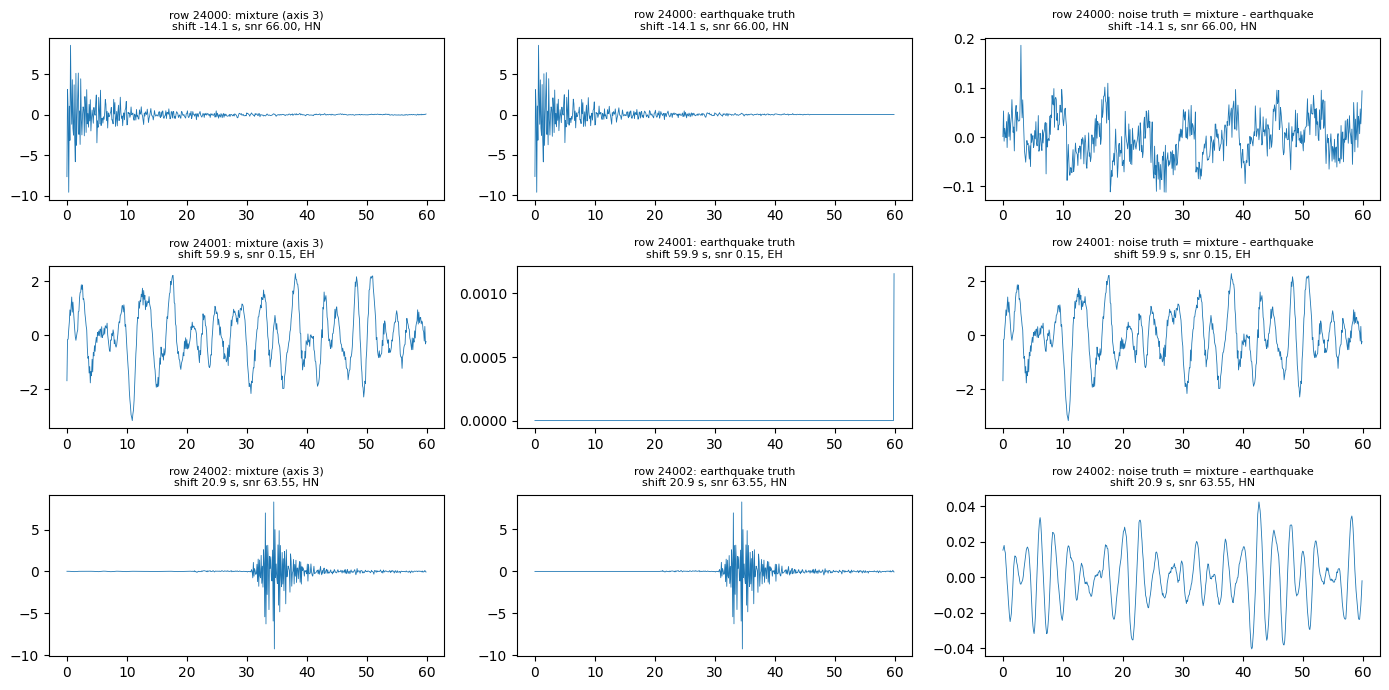

sha256[:16] of the output: 77f1f7963bf8ca70 (first 50 MB)
output size 665 MB


105

In [6]:
import numpy as np, h5py, matplotlib.pyplot as plt
path = os.path.join(OUT_DIR, "training_datasets_INSTANCE_snr40.hdf5")
rep = json.load(open(os.path.join(OUT_DIR, "instance_build_report.json")))
print("earthquake funnel:"); [print(f"  {k:55s}{v}") for k, v in rep["earthquake_funnel"]]
print("noise pool:", rep["noise_pool"]); print("split:", json.dumps(rep["split"]))
print("mixtures:", {k: v for k, v in rep["mixtures"].items() if k not in ("earthquake_use", "noise_use")})
print("earthquake reuse:", rep["mixtures"]["earthquake_use"]); print("noise reuse:", rep["mixtures"]["noise_use"])
with h5py.File(path, "r") as f:
    X, Y = f["X_train"], f["Y_train"]
    print("\nshapes", X.shape, Y.shape, X.dtype, "| keys:", sorted(f.keys()))
    assert X.shape == Y.shape and X.shape[1:] == (600, 3) and X.dtype == np.float64
    sp = f["split_id"][:]; src = f["source_id"][:]; nn = f["noise_name"][:].astype(str)
    for a, b in ((0, 1), (0, 2), (1, 2)):
        assert not (set(src[sp == a]) & set(src[sp == b])), "earthquake shared between splits"
        assert not (set(nn[sp == a]) & set(nn[sp == b])), "noise trace shared between splits"
    assert not (set(src) & set(EXCLUDE_SOURCE_IDS))
    xs = np.array([X[i] for i in range(0, X.shape[0], 500)])
    print("all finite:", bool(np.isfinite(xs).all()), "| per-component std of mixtures (should be 1):", np.round(xs.std(axis=1).mean(0), 4))
    print("split rows:", [int((sp == k).sum()) for k in range(3)], "| NO earthquake or noise trace is shared between train / val / test: OK")
    te = np.where(sp == 2)[0][:3]
    fig, ax = plt.subplots(3, 3, figsize=(14, 7)); tt = f["time"][:]
    for r_, i in enumerate(te):
        x, y = X[i][:, 2], Y[i][:, 2]
        for c_, (v, tl) in enumerate(((x, "mixture (axis 3)"), (y, "earthquake truth"), (x - y, "noise truth = mixture - earthquake"))):
            ax[r_, c_].plot(tt, v, lw=.6); ax[r_, c_].set_title(f"row {i}: {tl}\nshift {f['shift'][i]:.1f} s, snr {f['snr'][i]:.2f}, {f['station_channels'][i].decode()}", fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "check_examples_test_split.png"), dpi=110); plt.show()
print("sha256[:16] of the output:", hashlib.sha256(open(path, "rb").read(50_000_000)).hexdigest()[:16], "(first 50 MB)")
print(f"output size {os.path.getsize(path)/1e6:.0f} MB")
os.makedirs(os.path.join(WORK, "logs"), exist_ok=True)
open(os.path.join(WORK, "logs", "lab_log.md"), "a").write(f"- {time.strftime('%Y-%m-%d %H:%M')} build INSTANCE mixtures N={N_MIXTURES} snr>={SNR_MIN_DB} pre_p={PRE_P_S}s commit={COMMIT[:8]} script={hashlib.sha256(SCRIPT.encode()).hexdigest()[:8]}\n")

## After the run
1. *Save Version > Save & Run All (Commit)*. In the Output tab, create a **private Kaggle dataset** from `instance_mixtures/` (`training_datasets_INSTANCE_snr40.hdf5`, `instance_build_report.json`, the check plot).
2. Send me `instance_build_report.json` and `check_examples_test_split.png` and the printed checks.
3. Next: `step3` needs a small patch to use `split_id` (the repo's step3 splits randomly after loading, which would undo the split-before-mixing). That patch comes with the E3 notebook.

**Deviation log lines for this step** (copy into `results/deviation_log.md`):
- INSTANCE sample v3 (10,000 events from 300 earthquakes, 1,000 noise traces), raw counts for both classes.
- Earthquake pool: mean of E/N/Z SNR (INSTANCE definition, not STEAD's) >= 40 dB; 60 s window starting 10 s before the P pick; one earthquake dropped for a candidate overlap with STEAD.
- Noise: two non-overlapping 60 s windows per 120 s trace; windows are not guaranteed free of earthquakes.
- Split by earthquake and noise trace before mixing (repo: after mixing); new seeds 201 to 204; 30,000 mixtures instead of 100,000.